# Webcam word detection

This archived notebook runs the isolated-word GRID model in `archive/kaggle_lip_reading/checkpoints/best.pt` against a live webcam clip. The model was trained on **one word at a time**, so keep the recording short and minimise leading and trailing silence.

Run the cells in order. In the webcam preview, say one supported GRID word and press **q** immediately to stop recording and classify the captured mouth frames.

In [1]:
from pathlib import Path
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'archive' / 'kaggle_lip_reading' / 'checkpoints' / 'best.pt').is_file() and (candidate / 'models').is_dir():
            return candidate
    raise FileNotFoundError(
        'Could not find the VisionSpeak project root containing the archived GRID checkpoint.'
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from archive.kaggle_lip_reading.models.LBY.predict import get_device, load_model, prepare_frames
from processing.preprocessor import Preprocessor
from processing.video_loader import VideoLoader

print(f'Project root: {PROJECT_ROOT}')

Project root: C:\Users\Valente\OneDrive\Documents\NUS\Pattern Recognition System\Practice Module\VisionSpeak


In [2]:
CHECKPOINT_PATH = PROJECT_ROOT / 'archive' / 'kaggle_lip_reading' / 'checkpoints' / 'best.pt'
device = get_device()
model, index_to_word =load_model(CHECKPOINT_PATH, device)
print(f'Device: {device}')
print(f'Loaded checkpoint: {CHECKPOINT_PATH.name}')
print(f'Vocabulary size: {len(index_to_word)} words')

Device: cuda
Loaded checkpoint: best.pt
Vocabulary size: 51 words


## Record one word

Run the next cell. An OpenCV preview window opens with the full webcam view and a green box around the mouth crop passed to the model. Position your face in view, say **one** GRID vocabulary word, and then press **q**. The capture is released and the window closes automatically.

In [3]:
captured_frames = None
video_data = None

try:
    print('Full webcam preview started. Say one word, then press q to stop and predict.')
    video_data = VideoLoader().load('webcam', show_full_frame=True)
    if not video_data.get('loaded'):
        raise ValueError('No webcam frames were captured. Please try again.')

    video_data = Preprocessor().convert_to_greyscale(video_data)
    captured_frames = np.asarray(video_data['frames'], dtype=np.uint8)
    print(f'Captured {len(captured_frames)} mouth-crop frames.')
finally:
    if video_data is not None:
        capture = video_data.get('capture')
        if capture is not None:
            capture.release()
    cv2.destroyAllWindows()

Full webcam preview started. Say one word, then press q to stop and predict.
Captured 172 mouth-crop frames.


## Predict the word

This uses the same grayscale normalisation and tensor layout as the LBY training data, then reports the winner and the three most likely vocabulary words.

In [4]:
if captured_frames is None:
    raise RuntimeError('Run the webcam capture cell before running prediction.')

model_input = prepare_frames(captured_frames).to(device)
with torch.inference_mode():
    logits = model(model_input)
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu()

top_count = min(3, len(index_to_word))
top_probabilities, top_indices = torch.topk(probabilities, k=top_count)
top_predictions = [
    (index_to_word[int(index)], float(probability))
    for probability, index in zip(top_probabilities, top_indices)
]
predicted_word, confidence = top_predictions[0]

display(Markdown(f'## Prediction: **{predicted_word}** ({confidence:.1%})'))
for rank, (word, probability) in enumerate(top_predictions, start=1):
    print(f'{rank}. {word}: {probability:.1%}')

## Prediction: **in** (70.8%)

1. in: 70.8%
2. at: 19.0%
3. with: 9.2%


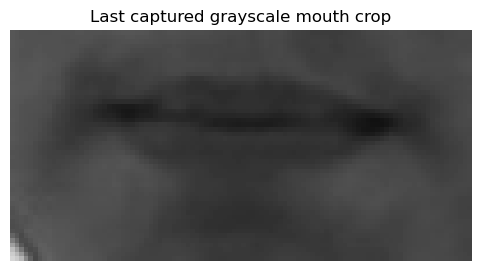

For best results, record only one word with minimal silence before or after it.


In [5]:
if captured_frames is None:
    raise RuntimeError('Run the webcam capture cell before inspecting frames.')

plt.figure(figsize=(6, 3))
plt.imshow(captured_frames[-1], cmap='gray', vmin=0, vmax=255)
plt.title('Last captured grayscale mouth crop')
plt.axis('off')
plt.show()

print('For best results, record only one word with minimal silence before or after it.')

## Notes

- The checkpoint recognises the 51 words in its GRID training vocabulary; it cannot identify arbitrary English words.
- The notebook does not save video. Re-run the capture, prediction, and inspection cells for another attempt.
- If no preview opens, make sure the Jupyter kernel has camera permission and is running in a local GUI-capable Python environment.